<a href="https://colab.research.google.com/github/rayyan-builds/Decision-Intelligence-Portfolio/blob/main/Bookstore_Intelligence_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Bookstore Intelligence Mission
**Web Scraping, Catalogue Analysis and Data-Driven Decision-Making**

**Student:** Rayyan Asim  |  **Roll Number:** 23i-5002  |  **Class:** BSBA-7B  |  **Subject:** Data Analytics and Python Programming

## Introduction and Objectives
A competitor has published its products online but will not share its dataset. This notebook turns the sandbox website [Books to Scrape](https://books.toscrape.com/) into a clean business dataset and uses it to support a purchasing decision. It combines all the mission scripts, with a short explanation after each step.

**Objectives**
1. Identify the HTML elements holding each book's title, price, rating and availability.
2. Scrape these fields, first from one page and then from several pages using a loop.
3. Store the records in a Pandas DataFrame and export `competitor_books.csv`.
4. Answer the seven analysis questions and make a business recommendation.
5. Solve the £100 CEO budget challenge.
6. Bonus work: scrape the full catalogue with product URLs, count ratings and chart them.

**Run order:** run the cells from top to bottom (*Kernel → Restart & Run All*). Requires an internet connection and the packages `requests`, `beautifulsoup4`, `pandas`, `numpy` and `matplotlib`.

In [1]:
import time
from urllib.parse import urljoin

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

BASE_URL = "https://books.toscrape.com/"

# The site stores ratings as words, so they are converted to numbers 1-5.
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

*Setup.* Requests downloads pages, BeautifulSoup parses the HTML, Pandas builds the tables, NumPy supports the CEO optimisation and Matplotlib draws the chart. `RATING_MAP` converts the rating words One–Five into integers so ratings can be averaged, filtered and counted.

---
## Mission 1: Reconnaissance (Understanding the Website Structure)
Before writing code, I opened an individual book page and inspected its HTML. The page contains markup specific to the selected book, and each item I needed sits in a predictable element:

| Data Field | HTML Element or Selector | Purpose |
|---|---|---|
| Book title | `<h1>` | Identifies the book (e.g. *Tipping the Velvet*) |
| Price | `p.price_color` | The displayed price (e.g. £53.74) |
| Rating | `p.star-rating` | The rating is stored in the class name (e.g. `star-rating One` means 1 star) |
| Availability | `p.instock.availability` | Stock information (e.g. "In stock (20 available)") |

On the catalogue listing pages, each book sits inside an `article.product_pod` element, which is what the scrapers below loop over.

---
## Mission 2: Capture the Data (first page)

In [2]:
# Step 1: download the first catalogue page
response = requests.get(BASE_URL, timeout=20)
response.raise_for_status()

# Step 2: parse the HTML
soup = BeautifulSoup(response.text, "html.parser")

# Step 3: extract the four fields from every book card
books = []
for book in soup.select("article.product_pod"):
    title = book.select_one("h3 a")["title"].strip()

    price_text = book.select_one(".price_color").get_text(strip=True)
    price = float(price_text.replace("£", "").replace("Â", ""))

    rating_element = book.select_one(".star-rating")
    rating_word = next(c for c in rating_element["class"] if c != "star-rating")
    rating = RATING_MAP[rating_word]

    availability = book.select_one(".availability").get_text(" ", strip=True)

    books.append({"Title": title, "Price": price,
                  "Rating": rating, "Availability": availability})

# Step 4: build a DataFrame
df_page1 = pd.DataFrame(books)
print("FIRST FIVE BOOKS")
print(df_page1.head())
print("\nTOTAL BOOKS SCRAPED:", len(df_page1))
print("COLUMNS:", df_page1.columns.tolist())

FIRST FIVE BOOKS
                                   Title  Price  Rating Availability
0                   A Light in the Attic  51.77       3     In stock
1                     Tipping the Velvet  53.74       1     In stock
2                             Soumission  50.10       1     In stock
3                          Sharp Objects  47.82       4     In stock
4  Sapiens: A Brief History of Humankind  54.23       5     In stock

TOTAL BOOKS SCRAPED: 20
COLUMNS: ['Title', 'Price', 'Rating', 'Availability']


 The scraper downloads the first page, selects every `article.product_pod`, and pulls out the title (from the link's `title` attribute), the price (with the £ symbol and stray `Â` character removed and converted to a float), the rating (the class word mapped to 1–5) and the availability text. It collects 20 books, which are stored in a DataFrame.

---
## Mission 3: Scale the Operation (three pages and CSV export)

In [3]:
TOTAL_PAGES = 3
all_books = []

for page_number in range(1, TOTAL_PAGES + 1):
    # Page 1 is the home page; later pages follow catalogue/page-N.html
    if page_number == 1:
        url = BASE_URL
    else:
        url = f"{BASE_URL}catalogue/page-{page_number}.html"

    print(f"Scraping page {page_number}: {url}")
    response = requests.get(url, timeout=20)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    book_cards = soup.select("article.product_pod")
    print("  Books found on this page:", len(book_cards))

    for book in book_cards:
        title = book.select_one("h3 a")["title"].strip()

        price_text = book.select_one(".price_color").get_text(strip=True)
        price = float(price_text.replace("£", "").replace("Â", ""))

        rating_element = book.select_one(".star-rating")
        rating_word = next(c for c in rating_element["class"] if c != "star-rating")
        rating = RATING_MAP[rating_word]

        availability = book.select_one(".availability").get_text(" ", strip=True)

        all_books.append({"Title": title, "Price": price,
                          "Rating": rating, "Availability": availability})

df = pd.DataFrame(all_books)

print("\nFIRST FIVE ROWS")
print(df.head())
print("\nDATASET DIMENSIONS:", df.shape)
print("\nCOLUMN NAMES:", df.columns.tolist())
print("\nMISSING VALUES")
print(df.isnull().sum())

df.to_csv("competitor_books.csv", index=False)
print("\nDataset successfully saved as competitor_books.csv")

Scraping page 1: https://books.toscrape.com/
  Books found on this page: 20
Scraping page 2: https://books.toscrape.com/catalogue/page-2.html
  Books found on this page: 20
Scraping page 3: https://books.toscrape.com/catalogue/page-3.html
  Books found on this page: 20

FIRST FIVE ROWS
                                   Title  Price  Rating Availability
0                   A Light in the Attic  51.77       3     In stock
1                     Tipping the Velvet  53.74       1     In stock
2                             Soumission  50.10       1     In stock
3                          Sharp Objects  47.82       4     In stock
4  Sapiens: A Brief History of Humankind  54.23       5     In stock

DATASET DIMENSIONS: (60, 4)

COLUMN NAMES: ['Title', 'Price', 'Rating', 'Availability']

MISSING VALUES
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Dataset successfully saved as competitor_books.csv


 The same extraction code now sits inside a loop over page numbers, so it is written once rather than copied three times. The result is the **original assignment dataset: 60 records** (3 pages × 20 books) with the columns Title, Price, Rating and Availability. The checks display the first rows, the shape, the column names and any missing values, and the data is saved as `competitor_books.csv`.

---
## Mission 4: Intelligence Analysis
The manager does not want raw HTML, so the dataset is used to answer seven questions.

In [4]:
df = pd.read_csv("competitor_books.csv")

print("Total books in dataset:", len(df))

# Q1: most expensive book
most_expensive = df.loc[df["Price"].idxmax()]
print("\n1. MOST EXPENSIVE BOOK")
print("Title:", most_expensive["Title"])
print("Price: £", round(most_expensive["Price"], 2))

# Q2: cheapest book
cheapest = df.loc[df["Price"].idxmin()]
print("\n2. CHEAPEST BOOK")
print("Title:", cheapest["Title"])
print("Price: £", round(cheapest["Price"], 2))

# Q3: average price
print("\n3. AVERAGE BOOK PRICE")
print("Average price: £", round(df["Price"].mean(), 2))

Total books in dataset: 60

1. MOST EXPENSIVE BOOK
Title: Slow States of Collapse: Poems
Price: £ 57.31

2. CHEAPEST BOOK
Title: In Her Wake
Price: £ 12.84

3. AVERAGE BOOK PRICE
Average price: £ 35.0


*Explanation (Q1–Q3).* `idxmax()` and `idxmin()` locate the most and least expensive rows, and `mean()` gives the average price. These show the price range of the competitor's catalogue.

In [5]:
# Q4: how many 5-star books?
five_star_books = df[df["Rating"] == 5]
print("4. FIVE-STAR BOOKS")
print("Number of 5-star books:", len(five_star_books))

# Q5: percentage in stock
in_stock = df["Availability"].str.contains("In stock", case=False, na=False)
in_stock_percentage = in_stock.sum() / len(df) * 100 if len(df) > 0 else 0
print("\n5. BOOK AVAILABILITY")
print("Books in stock:", in_stock.sum())
print("Percentage in stock:", round(in_stock_percentage, 2), "%")

4. FIVE-STAR BOOKS
Number of 5-star books: 14

5. BOOK AVAILABILITY
Books in stock: 60
Percentage in stock: 100.0 %


*Explanation (Q4–Q5).* Filtering on `Rating == 5` counts the top-rated books. A text search for "In stock" gives the availability percentage.

In [6]:
# Q6: top 5 highest-rated books (ties broken by lower price)
top_five = df.sort_values(by=["Rating", "Price"], ascending=[False, True]).head(5)
print("6. TOP 5 HIGHEST-RATED BOOKS")
print(top_five[["Title", "Price", "Rating"]].to_string(index=False))

# Q7: cheapest 5-star book
if not five_star_books.empty:
    cheapest_five_star = five_star_books.loc[five_star_books["Price"].idxmin()]
    print("\n7. CHEAPEST FIVE-STAR BOOK")
    print("Title:", cheapest_five_star["Title"])
    print("Price: £", round(cheapest_five_star["Price"], 2))
else:
    print("\n7. No 5-star books were found.")

6. TOP 5 HIGHEST-RATED BOOKS
                                                             Title  Price  Rating
                                                    Sophie's World  15.94       5
                                                            Thirst  17.27       5
                                                       Set Me Free  17.46       5
        The Four Agreements: A Practical Guide to Personal Freedom  17.66       5
#HigherSelfie: Wake Up Your Life. Free Your Soul. Find Your Tribe.  23.11       5

7. CHEAPEST FIVE-STAR BOOK
Title: Sophie's World
Price: £ 15.94


*Explanation (Q6–Q7).* Sorting by rating (high to low) and then price (low to high) gives the five best-rated books, with cheaper books ranked first when ratings tie. The cheapest 5-star book is found with `idxmin()` on the filtered data.

**Answers (from the 60-book dataset)**

| # | Question | Answer |
|---|---|---|
| 1 | Most expensive book | *Slow States of Collapse: Poems* — £57.31 |
| 2 | Cheapest book | *In Her Wake* — £12.84 |
| 3 | Average price | £35.00 |
| 4 | Books rated 5 stars | 14 of 60 (23.3%) |
| 5 | Books in stock | 100% (all 60) |
| 6 | Top 5 highest-rated | *Sophie's World; Thirst; Set Me Free; The Four Agreements; #HigherSelfie* |
| 7 | Cheapest 5-star book | *Sophie's World* — £15.94 |

### Business Decision: Manager's Question
*Which books would you prioritise for a competing online bookstore, and why?* The code below filters the five-star books, sorts them by price, shows the five cheapest and exports the full list.

In [7]:
five_star_sorted = (
    df[df["Rating"] == 5]
    .sort_values(by="Price", ascending=True)
    .reset_index(drop=True)
)

print("TOP 5 CHEAPEST FIVE-STAR BOOKS")
print(five_star_sorted.head(5)[["Title", "Price", "Rating", "Availability"]].to_string(index=False))

five_star_sorted[["Title", "Price", "Rating", "Availability"]].to_csv(
    "five_star_books_by_price.csv", index=False, encoding="utf-8-sig"
)
print("\nExported", len(five_star_sorted), "five-star books to five_star_books_by_price.csv")

TOP 5 CHEAPEST FIVE-STAR BOOKS
                                                             Title  Price  Rating Availability
                                                    Sophie's World  15.94       5     In stock
                                                            Thirst  17.27       5     In stock
                                                       Set Me Free  17.46       5     In stock
        The Four Agreements: A Practical Guide to Personal Freedom  17.66       5     In stock
#HigherSelfie: Wake Up Your Life. Free Your Soul. Find Your Tribe.  23.11       5     In stock

Exported 14 five-star books to five_star_books_by_price.csv


**Recommendation.** I would prioritise the five cheapest five-star books: *Sophie's World* (£15.94), *Thirst* (£17.27), *Set Me Free* (£17.46), *The Four Agreements* (£17.66) and *#HigherSelfie* (£23.11). The data supports this with two pieces of evidence: all five cost well below the dataset's average price of £35.00, and all five carry the highest displayed rating (5 stars) and are in stock. This gives an affordable, well-rated starting catalogue.

*Caveat:* Books to Scrape assigns ratings at random and the dataset contains no sales or demand data, so this is preliminary market research and not proof that these books would sell well.

---
## Final Challenge: The CEO Has £100
The CEO wants the books that **maximise the total star rating** without spending more than **£100**. This is a budget-constrained optimisation problem, solved as a **0/1 knapsack** with dynamic programming: each book's price is its cost and its rating is its value. Prices are converted to whole pence so the £100 budget (10,000 pence) is handled exactly.

In [8]:
BUDGET_POUNDS = 100
BUDGET_PENCE = BUDGET_POUNDS * 100

ceo_df = pd.read_csv("competitor_books.csv")
ceo_df["Price"] = pd.to_numeric(ceo_df["Price"], errors="coerce")
ceo_df["Rating"] = pd.to_numeric(ceo_df["Rating"], errors="coerce")
ceo_df = ceo_df.dropna(subset=["Title", "Price", "Rating"]).copy()
ceo_df = ceo_df[(ceo_df["Price"] > 0) & (ceo_df["Rating"].between(1, 5))].copy()

# Convert prices to integer pence and drop books that alone exceed the budget
ceo_df["Price_Pence"] = (ceo_df["Price"] * 100).round().astype(int)
ceo_df = ceo_df[ceo_df["Price_Pence"] <= BUDGET_PENCE].reset_index(drop=True)

n = len(ceo_df)
budget = BUDGET_PENCE

# dp[i, b] = best total rating using the first i books with at most b pence
dp = np.zeros((n + 1, budget + 1), dtype=np.int32)

for i in range(1, n + 1):
    price = int(ceo_df.loc[i - 1, "Price_Pence"])
    rating = int(ceo_df.loc[i - 1, "Rating"])

    dp[i] = dp[i - 1]                                   # option A: skip the book
    dp[i, price:] = np.maximum(                         # option B: buy it if affordable
        dp[i - 1, price:],
        dp[i - 1, :budget - price + 1] + rating
    )

# Trace back which books make up the optimal solution
selected_indices = []
remaining = budget
for i in range(n, 0, -1):
    if dp[i, remaining] != dp[i - 1, remaining]:
        selected_indices.append(i - 1)
        remaining -= int(ceo_df.loc[i - 1, "Price_Pence"])
selected_indices.reverse()

selected_books = ceo_df.iloc[selected_indices].copy()
total_cost_pence = int(selected_books["Price_Pence"].sum())

print("OPTIMAL BOOK SELECTION")
print(selected_books[["Title", "Price", "Rating"]].to_string(index=False))

print("\nFINAL RESULTS")
print("Number of books selected:", len(selected_books))
print(f"Total cost: £{total_cost_pence / 100:.2f}")
print("Combined rating score:", int(selected_books["Rating"].sum()))
print(f"Remaining budget: £{(BUDGET_PENCE - total_cost_pence) / 100:.2f}")
print("Budget constraint:", "PASSED" if total_cost_pence <= BUDGET_PENCE else "FAILED")

OPTIMAL BOOK SELECTION
                                                     Title  Price  Rating
            Starving Hearts (Triangular Trade Trilogy, #1)  13.99       2
                                               Set Me Free  17.46       5
The Four Agreements: A Practical Guide to Personal Freedom  17.66       5
                                            Sophie's World  15.94       5
                   Untitled Collection: Sabbath Poems 2014  14.27       4
                                                    Thirst  17.27       5

FINAL RESULTS
Number of books selected: 6
Total cost: £96.59
Combined rating score: 26
Remaining budget: £3.41
Budget constraint: PASSED


*Explanation.* The table `dp` stores the best rating total achievable for every budget level, deciding book by book whether to buy or skip it. Tracing back through the table recovers the chosen books.

**CEO answer**

| Book | Price | Rating |
|---|---|---|
| Starving Hearts (Triangular Trade Trilogy, #1) | £13.99 | 2 |
| Set Me Free | £17.46 | 5 |
| The Four Agreements: A Practical Guide to Personal Freedom | £17.66 | 5 |
| Sophie's World | £15.94 | 5 |
| Untitled Collection: Sabbath Poems 2014 | £14.27 | 4 |
| Thirst | £17.27 | 5 |

**6 books, total cost £96.59, combined rating score 26, £3.41 remaining.** This is optimal only for the stated objective (sum of star ratings under £100). It does not account for real demand, profit margins, shipping costs or customer preferences.

---
## Bonus Missions and Boss Level
The bonus work extends the scraper to the **entire catalogue**, adds **product URLs**, **counts books by star rating** and **plots a bar chart**. Results are saved to new files so the original `competitor_books.csv` is not overwritten.

In [9]:
CSV_FILENAME = "competitor_books_bonus.csv"
RATING_COUNTS_FILENAME = "rating_counts.csv"
CHART_FILENAME = "book_rating_distribution.png"
HEADERS = {"User-Agent": "Mozilla/5.0"}


def get_soup(page_url):
    """Download a webpage and return its parsed HTML."""
    response = requests.get(page_url, headers=HEADERS, timeout=30)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")


def extract_rating(rating_element):
    """Convert a textual star rating into a number from 1 to 5."""
    if rating_element is None:
        return None
    rating_classes = rating_element.get("class", [])
    for word, number in RATING_MAP.items():
        if word in rating_classes:
            return number
    return None


def extract_books(soup, page_url):
    """Extract book details (including the product URL) from one catalogue page."""
    books = []
    for book in soup.select("article.product_pod"):
        title_element = book.select_one("h3 a")
        if title_element is None:
            continue

        title = title_element.get("title", "").strip()
        product_url = urljoin(page_url, title_element.get("href", ""))

        price_element = book.select_one(".price_color")
        if price_element is None:
            price = None
        else:
            price_text = (price_element.get_text(strip=True)
                          .replace("Â", "").replace("£", "").strip())
            try:
                price = float(price_text)
            except ValueError:
                price = None

        rating = extract_rating(book.select_one("p.star-rating"))

        availability_element = book.select_one(".availability")
        availability = (availability_element.get_text(" ", strip=True)
                        if availability_element is not None else "Unknown")

        books.append({"Title": title, "Price": price, "Rating": rating,
                      "Availability": availability, "Product URL": product_url})
    return books

*Explanation.* The extraction logic is now in reusable functions. `extract_books` also records each book's **product URL** (Bonus 2) and handles missing elements safely.

In [10]:
def scrape_all_pages():
    """Follow the 'Next' link until no further page remains."""
    all_books, visited_urls = [], set()
    current_url, total_pages = BASE_URL, 0

    while current_url:
        if current_url in visited_urls:          # safety check against loops
            print("Repeated page detected. Stopping scraper.")
            break
        visited_urls.add(current_url)

        soup = get_soup(current_url)
        page_books = extract_books(soup, current_url)
        all_books.extend(page_books)
        total_pages += 1
        print(f"Page {total_pages}: {len(page_books)} books | total collected: {len(all_books)}")

        next_link = soup.select_one("li.next a")
        current_url = urljoin(current_url, next_link.get("href", "")) if next_link else None

        if current_url:
            time.sleep(0.2)                      # short pause between requests

    return all_books, total_pages


bonus_books, total_pages = scrape_all_pages()

bonus_df = pd.DataFrame(bonus_books)
bonus_df["Price"] = pd.to_numeric(bonus_df["Price"], errors="coerce")
bonus_df["Rating"] = pd.to_numeric(bonus_df["Rating"], errors="coerce").astype("Int64")

bonus_df.to_csv(CSV_FILENAME, index=False, encoding="utf-8-sig")

print("\nPages scraped:", total_pages)
print("Book records collected:", len(bonus_df))
print("Records with product URLs:", bonus_df["Product URL"].notna().sum())
print("Saved as:", CSV_FILENAME)
print("Boss Level:", "PASS (50 pages, 1,000 books)" if total_pages == 50 and len(bonus_df) == 1000
      else "CHECK: differs from the expected 50 pages / 1,000 books")

Page 1: 20 books | total collected: 20
Page 2: 20 books | total collected: 40
Page 3: 20 books | total collected: 60
Page 4: 20 books | total collected: 80
Page 5: 20 books | total collected: 100
Page 6: 20 books | total collected: 120
Page 7: 20 books | total collected: 140
Page 8: 20 books | total collected: 160
Page 9: 20 books | total collected: 180
Page 10: 20 books | total collected: 200
Page 11: 20 books | total collected: 220
Page 12: 20 books | total collected: 240
Page 13: 20 books | total collected: 260
Page 14: 20 books | total collected: 280
Page 15: 20 books | total collected: 300
Page 16: 20 books | total collected: 320
Page 17: 20 books | total collected: 340
Page 18: 20 books | total collected: 360
Page 19: 20 books | total collected: 380
Page 20: 20 books | total collected: 400
Page 21: 20 books | total collected: 420
Page 22: 20 books | total collected: 440
Page 23: 20 books | total collected: 460
Page 24: 20 books | total collected: 480
Page 25: 20 books | total col

*Explanation (Bonus 1, Bonus 2, Boss Level).* Instead of a fixed page count, the scraper keeps following the site's "next page" link until none is left, so it covers the whole catalogue with the same reusable logic. The full run collects **1,000 records across 50 pages**, each with a product URL, saved as `competitor_books_bonus.csv`.

In [11]:
# Bonus 3: count books at each star-rating level
rating_counts = (bonus_df["Rating"].value_counts()
                 .reindex([1, 2, 3, 4, 5], fill_value=0).sort_index())
rating_summary = pd.DataFrame({"Star Rating": rating_counts.index,
                               "Number of Books": rating_counts.values})
print(rating_summary.to_string(index=False))
rating_summary.to_csv(RATING_COUNTS_FILENAME, index=False, encoding="utf-8-sig")
print("\nSaved as:", RATING_COUNTS_FILENAME)

 Star Rating  Number of Books
           1              226
           2              196
           3              203
           4              179
           5              196

Saved as: rating_counts.csv


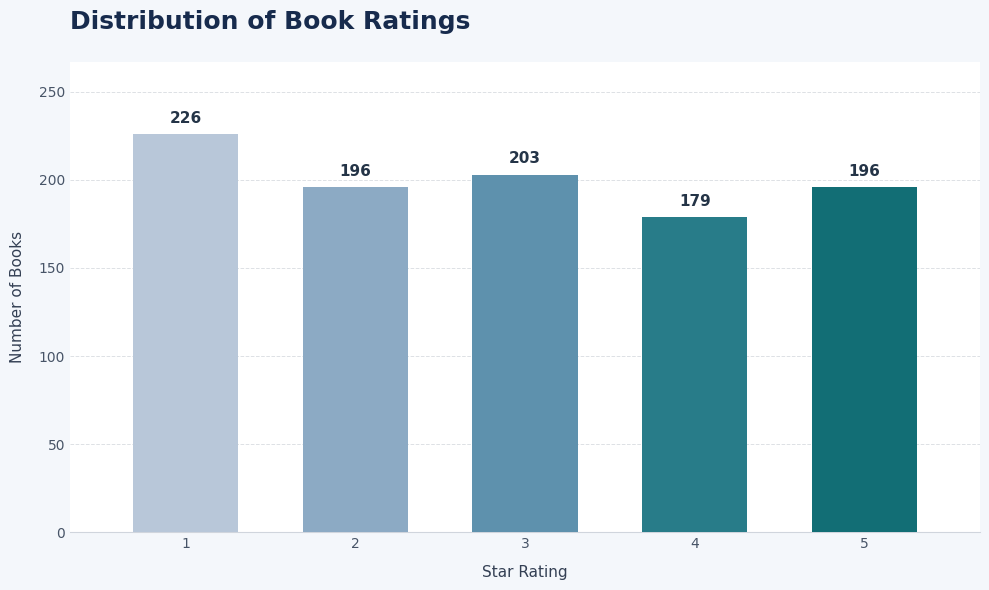

Chart saved as: book_rating_distribution.png


In [12]:

# Bonus 4: Professional bar chart of rating counts
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#B8C7D9", "#8CAAC4", "#5E91AD", "#287C89", "#126E75"]

bars = ax.bar(
    rating_summary["Star Rating"].astype(str),
    rating_summary["Number of Books"],
    color=colors,
    width=0.62,
    edgecolor="none",
    zorder=3
)

# Display the count above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#243447"
    )

# Title and axis labels
ax.set_title(
    "Distribution of Book Ratings",
    fontsize=18,
    fontweight="bold",
    color="#172B4D",
    loc="left",
    pad=24
)

ax.set_xlabel("Star Rating", fontsize=11, labelpad=10, color="#344054")
ax.set_ylabel("Number of Books", fontsize=11, labelpad=10, color="#344054")

# Clean background and subtle horizontal gridlines
fig.patch.set_facecolor("#F4F7FB")
ax.set_facecolor("#FFFFFF")
ax.set_ylim(0, rating_summary["Number of Books"].max() * 1.18)
ax.yaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.25, color="#7B8794")
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#D0D5DD")

ax.tick_params(axis="both", labelsize=10, colors="#475467", length=0)
ax.margins(x=0.08)

plt.tight_layout()
plt.savefig(
    CHART_FILENAME,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)
plt.show()

print("Chart saved as:", CHART_FILENAME)


**Figure 1. Distribution of books across the displayed star-rating categories.**

![Rating distribution](attachment:book_rating_distribution.png)

*Interpretation.* Across the 1,000 books, the counts for 1 to 5 stars are 226, 196, 203, 179 and 196 (22.6%, 19.6%, 20.3%, 17.9% and 19.6%). The distribution is fairly even: one-star books are the largest group, four-star books the smallest, and the gap between them is 47 books. Because Books to Scrape assigns ratings at random, this pattern says nothing about real customer sentiment.

---
## Conclusion
This notebook converted a website with no downloadable data into structured datasets: **60 records** for the assignment missions and **1,000 records** for the full catalogue. It demonstrates multi-page scraping with reusable logic, descriptive analysis of prices and ratings, a data-driven business recommendation, visualisation with Matplotlib, and budget-constrained optimisation with dynamic programming. The same workflow of collecting, structuring, analysing and recommending underpins much of business analytics.

**Limitations.** The ratings on Books to Scrape are randomly assigned and the data contains no sales, demand or customer-preference information, so the findings demonstrate technique rather than genuine market insight. In the CSV files one title (*The Star-Touched Queen*) appears twice, and a few titles show character-encoding artefacts (for example "Shakespeareâs Globe"); these were left as scraped and do not affect the analysis.

**Files produced by this notebook:** `competitor_books.csv`, `five_star_books_by_price.csv`, `competitor_books_bonus.csv`, `rating_counts.csv`, `book_rating_distribution.png`.